<a href="https://colab.research.google.com/github/manishthakur9349/Statistical-Foundation-of-Data-Science/blob/main/Practical10ManishThakurWine_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wine Dataset – Statistics, Visualization, Covariance, Scaling & PCA

**Tasks covered**
1. Basic statistics using `describe()`
2. Boxplot by output labels/classes
3. Scatterplot using two variables
4. Plot the Covariance Matrix
5. Data Scaling
6. Better class separation using Principal Components

## Importing the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style('whitegrid')

## Loading the dataset

In Google Colab, upload `wine.csv` using the **Files** panel on the left (or run `from google.colab import files; files.upload()`).

In [ ]:
df = pd.read_csv('wine.csv')
print('Shape of the dataset:', df.shape)
df.head()

Shape of the dataset: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [ ]:
print('Missing values:', df.isnull().sum().sum())
print('\nClass counts:')
print(df['class'].value_counts())

Missing values: 0

Class counts:
class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


# Step 1: Basic Statistics using `describe()`

In [ ]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


# Step 2: Boxplot by output labels / classes

One boxplot per feature, grouped by wine class.

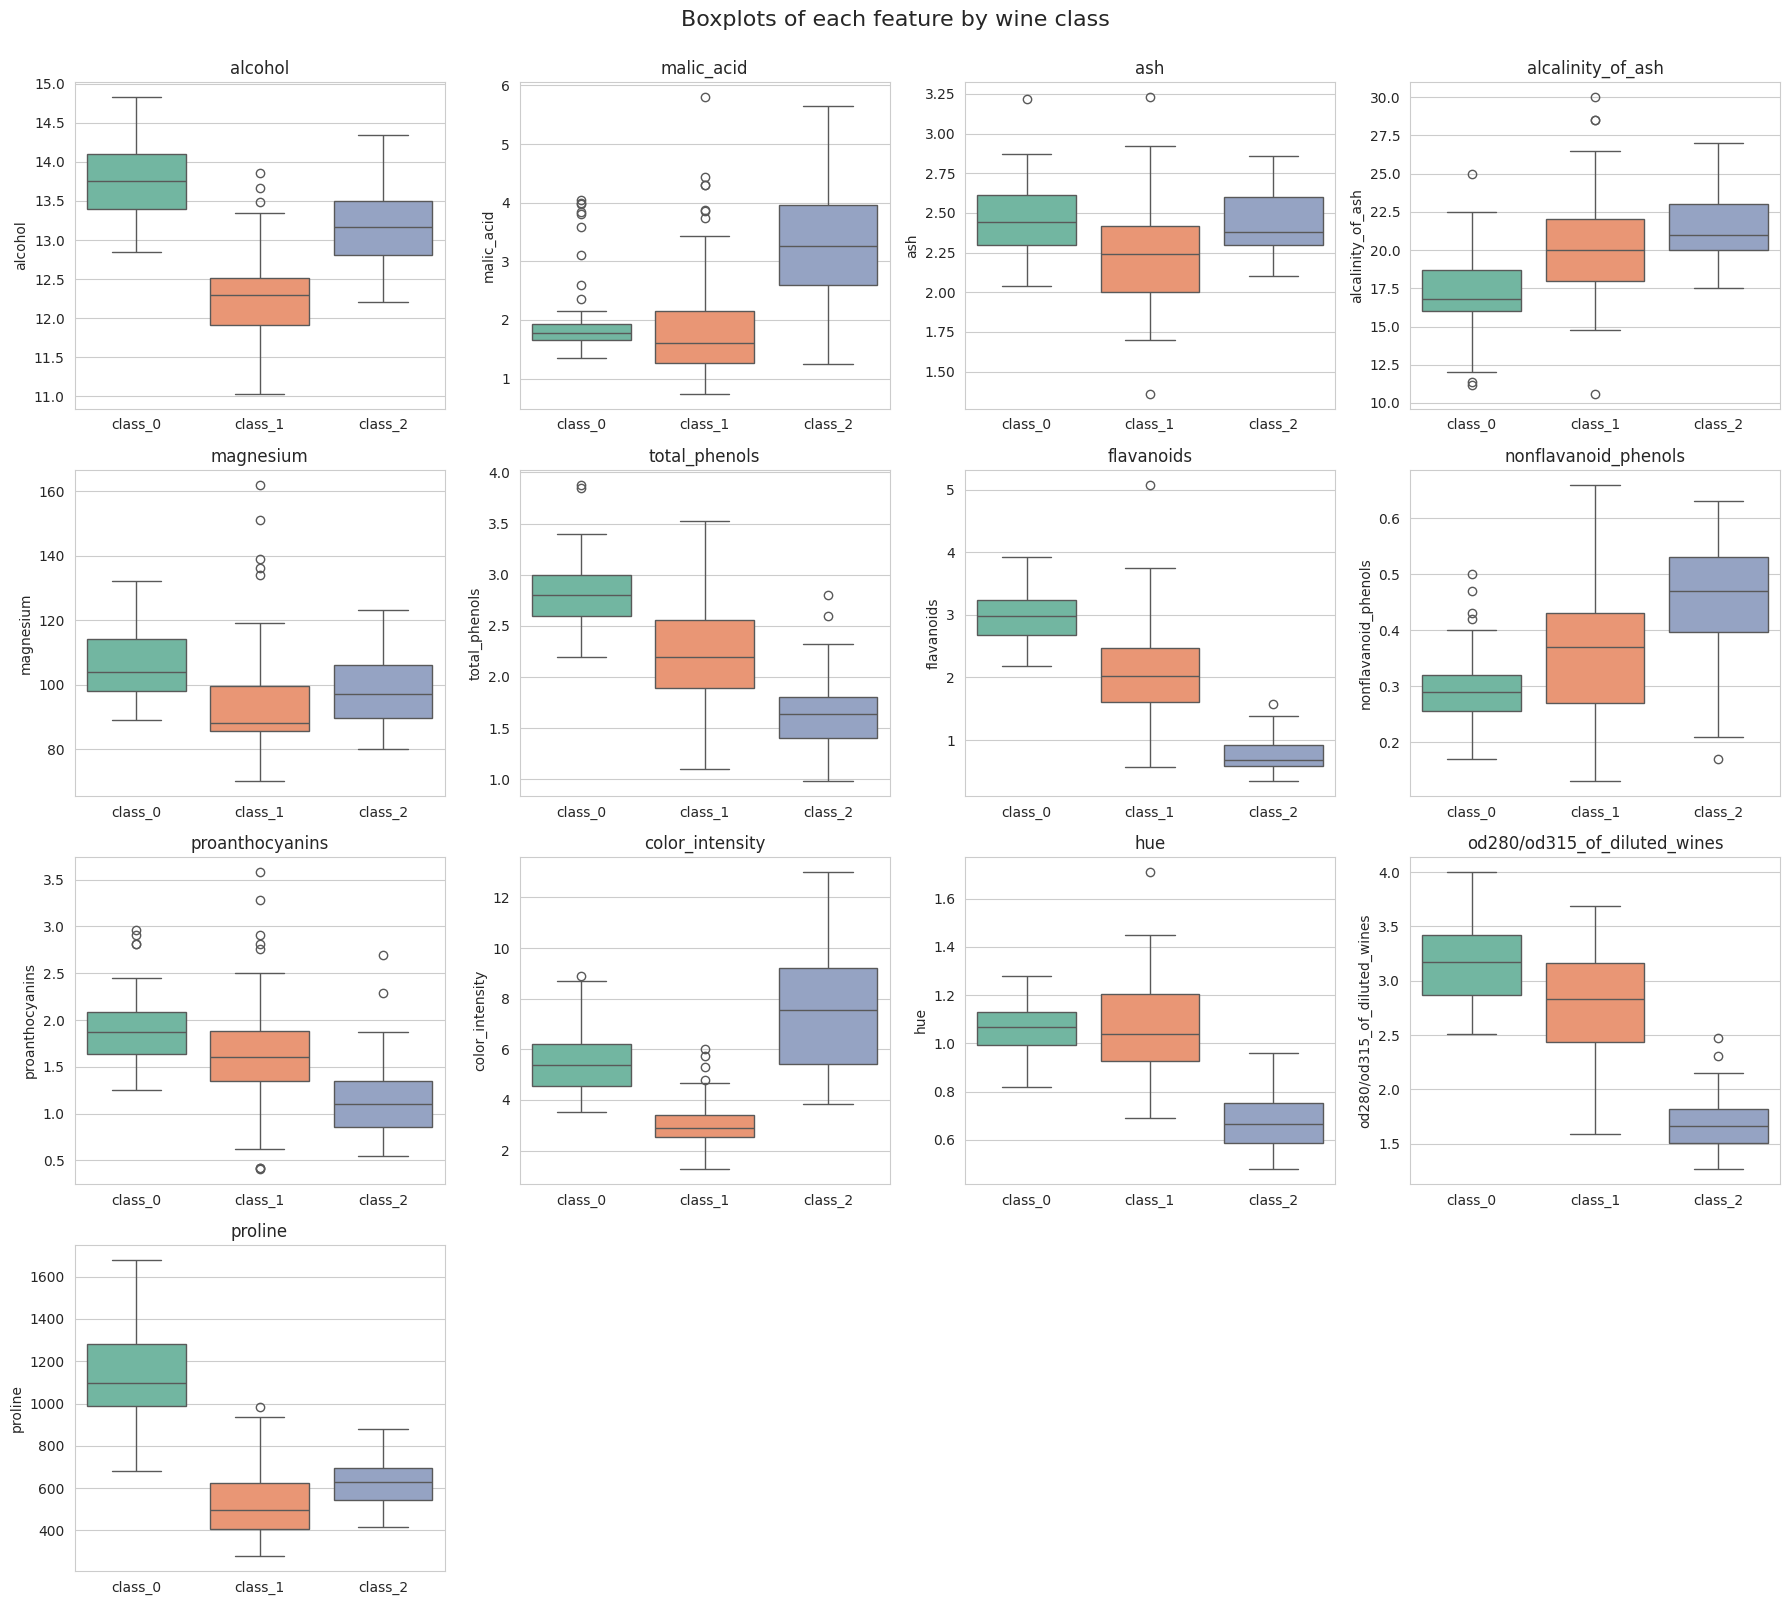

In [ ]:
features = df.columns.drop('class')

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.ravel()
for ax, col in zip(axes, features):
    sns.boxplot(x='class', y=col, data=df, hue='class', palette='Set2', legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
for ax in axes[len(features):]:
    ax.set_visible(False)
plt.suptitle('Boxplots of each feature by wine class', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

# Step 3: Scatterplot using two variables

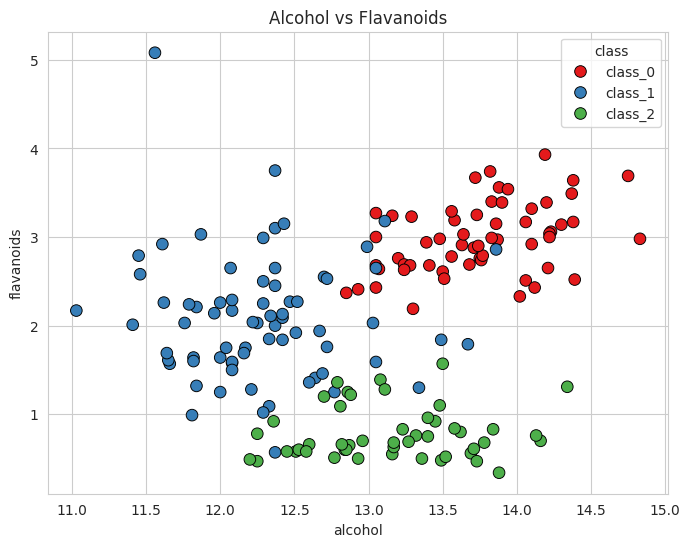

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='alcohol', y='flavanoids', hue='class',
                palette='Set1', s=70, edgecolor='black')
plt.title('Alcohol vs Flavanoids')
plt.show()

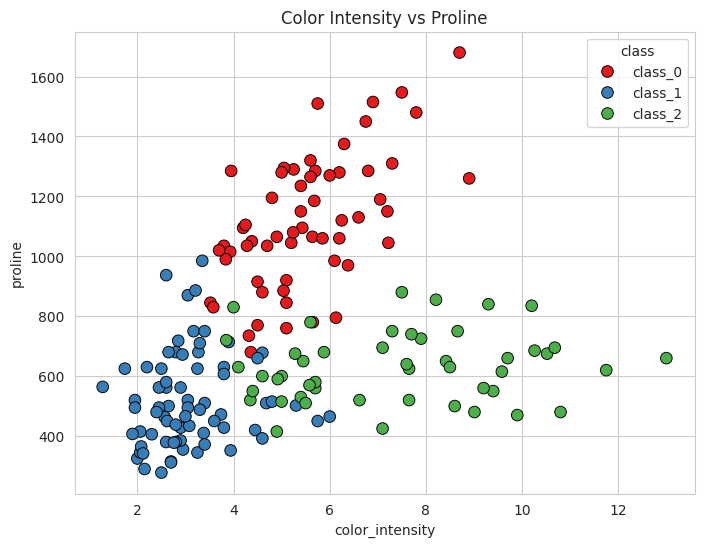

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='color_intensity', y='proline', hue='class',
                palette='Set1', s=70, edgecolor='black')
plt.title('Color Intensity vs Proline')
plt.show()

# Step 4: Plot the Co-Variance Matrix

In [ ]:
X = df.drop('class', axis=1)
cov_matrix = X.cov()
cov_matrix.round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
alcohol,0.66,0.09,0.05,-0.84,3.14,0.15,0.19,-0.02,0.06,1.03,-0.01,0.04,164.57
malic_acid,0.09,1.25,0.05,1.08,-0.87,-0.23,-0.46,0.04,-0.14,0.64,-0.14,-0.29,-67.55
ash,0.05,0.05,0.08,0.41,1.12,0.02,0.03,0.01,0.00,0.16,-0.00,0.00,19.32
alcalinity_of_ash,-0.84,1.08,0.41,11.15,-3.97,-0.67,-1.17,0.15,-0.38,0.15,-0.21,-0.66,-463.36
magnesium,3.14,-0.87,1.12,-3.97,203.99,1.92,2.79,-0.46,1.93,6.62,0.18,0.67,1769.16
total_phenols,0.15,-0.23,0.02,-0.67,1.92,0.39,0.54,-0.04,0.22,-0.08,0.06,0.31,98.17
flavanoids,0.19,-0.46,0.03,-1.17,2.79,0.54,1.00,-0.07,0.37,-0.40,0.12,0.56,155.45
nonflavanoid_phenols,-0.02,0.04,0.01,0.15,-0.46,-0.04,-0.07,0.02,-0.03,0.04,-0.01,-0.04,-12.20
proanthocyanins,0.06,-0.14,0.00,-0.38,1.93,0.22,0.37,-0.03,0.33,-0.03,0.04,0.21,59.55
color_intensity,1.03,0.64,0.16,0.15,6.62,-0.08,-0.40,0.04,-0.03,5.37,-0.28,-0.71,230.77


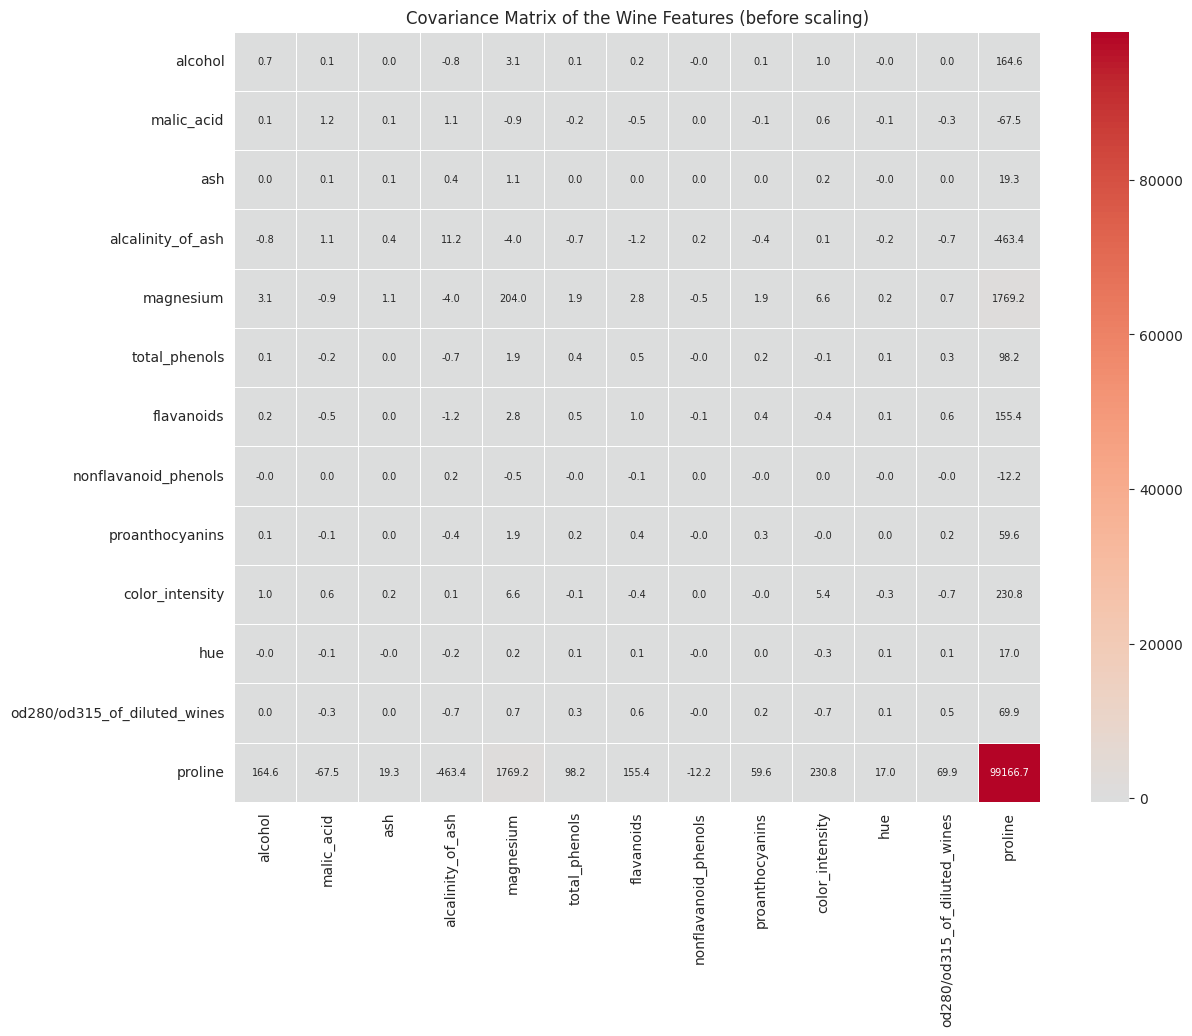

In [ ]:
plt.figure(figsize=(13, 10))
sns.heatmap(cov_matrix, annot=True, fmt='.1f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 7})
plt.title('Covariance Matrix of the Wine Features (before scaling)')
plt.show()

`proline` has a huge variance compared with the other features, so it dominates the raw covariance matrix. This is why scaling is needed before PCA.

# Step 5: Data Scaling

We standardize every feature to mean = 0 and standard deviation = 1 using `StandardScaler`.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print('Mean of scaled features (approx. 0):')
print(X_scaled_df.mean().round(3) + 0.0)
print('\nStd of scaled features (1):')
print(X_scaled_df.std(ddof=0).round(3))

Mean of scaled features (approx. 0):
alcohol                         0.0
malic_acid                      0.0
ash                             0.0
alcalinity_of_ash               0.0
magnesium                       0.0
total_phenols                   0.0
flavanoids                      0.0
nonflavanoid_phenols            0.0
proanthocyanins                 0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                         0.0
dtype: float64

Std of scaled features (1):
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline            

In [ ]:
X_scaled_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


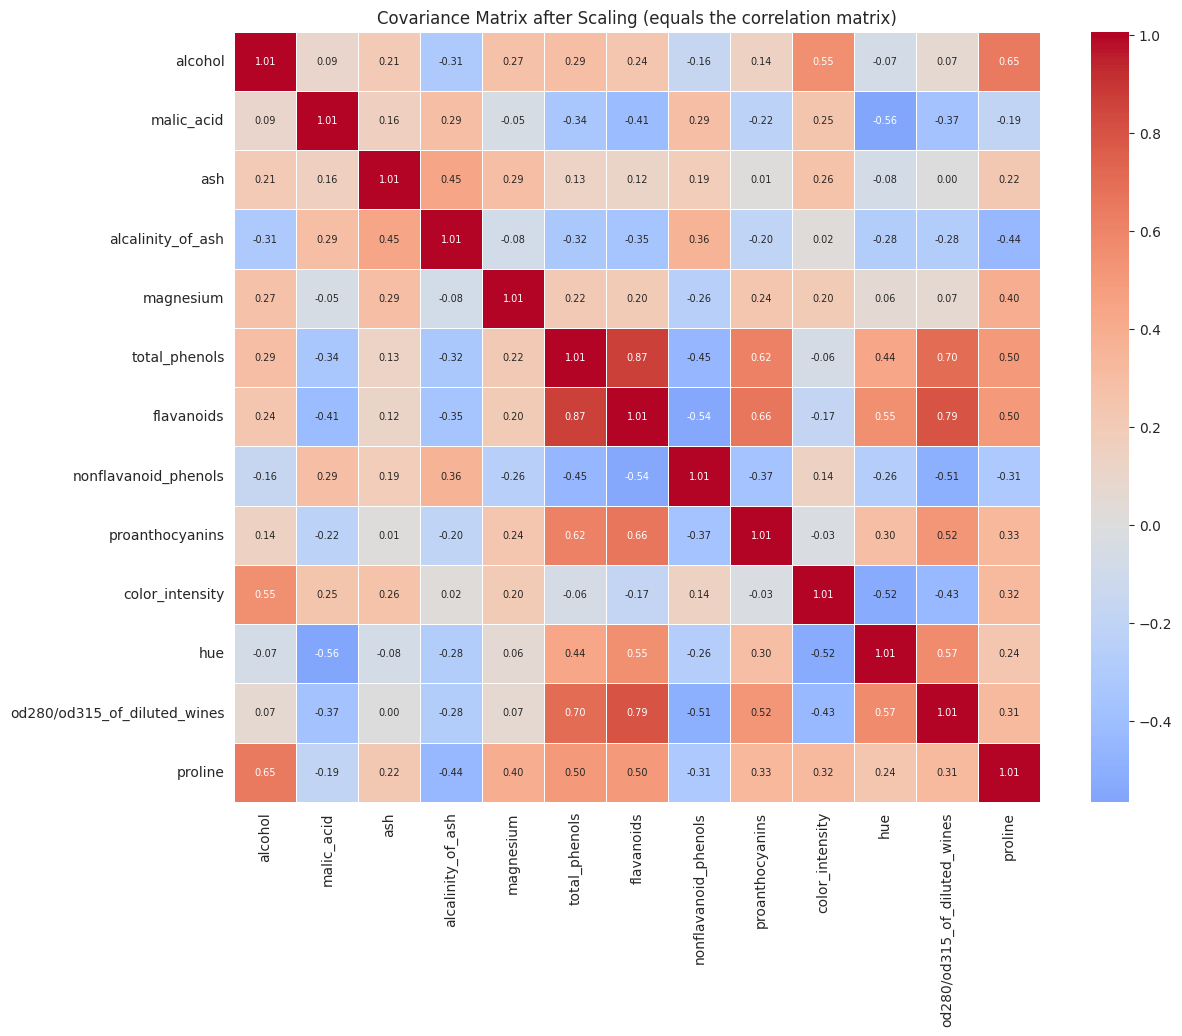

In [ ]:
plt.figure(figsize=(13, 10))
sns.heatmap(X_scaled_df.cov(), annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, annot_kws={'size': 7})
plt.title('Covariance Matrix after Scaling (equals the correlation matrix)')
plt.show()

# Step 6: Better class separation using Principal Components

In [ ]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
print('Explained variance ratio of each PC:')
for i, e in enumerate(explained, 1):
    print(f'PC{i}: {e:.4f}')
print('\nPC1 + PC2 together explain', round(explained[:2].sum() * 100, 2), '% of the variance')
print('First 3 PCs together explain', round(explained[:3].sum() * 100, 2), '% of the variance')

Explained variance ratio of each PC:
PC1: 0.3620
PC2: 0.1921
PC3: 0.1112
PC4: 0.0707
PC5: 0.0656
PC6: 0.0494
PC7: 0.0424
PC8: 0.0268
PC9: 0.0222
PC10: 0.0193
PC11: 0.0174
PC12: 0.0130
PC13: 0.0080

PC1 + PC2 together explain 55.41 % of the variance
First 3 PCs together explain 66.53 % of the variance


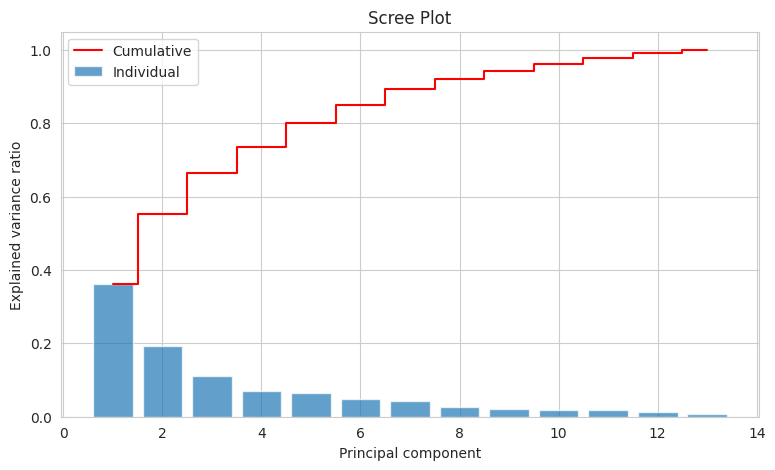

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(range(1, 14), explained, alpha=0.7, label='Individual')
plt.step(range(1, 14), np.cumsum(explained), where='mid', color='red', label='Cumulative')
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.title('Scree Plot')
plt.legend()
plt.show()

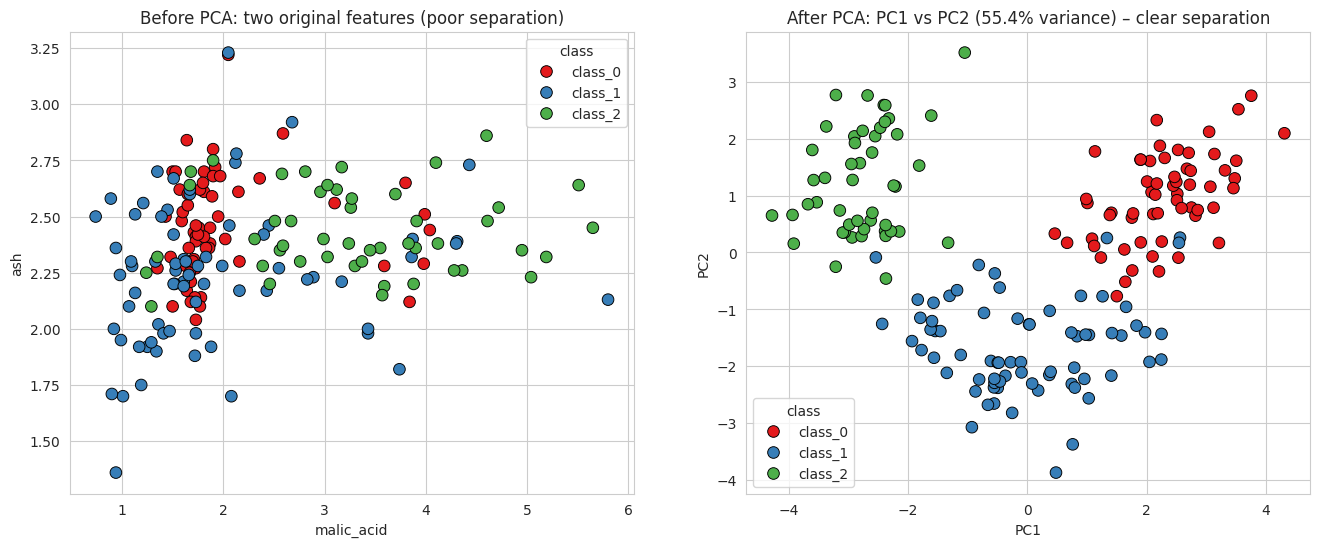

In [ ]:
pca_df = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
pca_df['class'] = df['class']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Before PCA: two raw features
sns.scatterplot(data=df, x='malic_acid', y='ash', hue='class', palette='Set1',
                s=70, edgecolor='black', ax=axes[0])
axes[0].set_title('Before PCA: two original features (poor separation)')

# After PCA: first two principal components
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='class', palette='Set1',
                s=70, edgecolor='black', ax=axes[1])
axes[1].set_title(f'After PCA: PC1 vs PC2 ({explained[:2].sum()*100:.1f}% variance) – clear separation')
plt.show()

In [ ]:
# Which original features contribute most to PC1 and PC2?
loadings = pd.DataFrame(pca.components_[:2].T, columns=['PC1', 'PC2'], index=X.columns)
loadings.round(3).sort_values('PC1', key=abs, ascending=False)

,PC1,PC2
flavanoids,0.423,-0.003
total_phenols,0.395,0.065
od280/od315_of_diluted_wines,0.376,-0.164
proanthocyanins,0.313,0.039
nonflavanoid_phenols,-0.299,0.029
hue,0.297,-0.279
proline,0.287,0.365
malic_acid,-0.245,0.225
alcalinity_of_ash,-0.239,-0.011
alcohol,0.144,0.484


## Conclusion

- `describe()` shows the features are on very different scales (e.g. `proline` in the hundreds, `hue` below 2).
- Boxplots and scatterplots show that several features (flavanoids, proline, color intensity, alcohol) differ between classes.
- The raw covariance matrix is dominated by `proline`, so the data was standardized.
- After scaling, the first two principal components capture about 55% of the variance and separate the three wine classes far better than any two original features.